In [101]:
!pip install opacus


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [102]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np
import time
import random


from tqdm import tqdm
from opacus import PrivacyEngine
from sklearn.metrics import f1_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using: ", device)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

Using:  cuda


In [103]:
# Hyperparameters
BATCH_SIZE = 64 # Feed the model the specified batch_size in parallel
EPOCHS = 15
LR = 0.001

# Differential Privacy Params
EPSILONS = [2.0, 5.0, 50]
DELTA = 1e-5
MAX_GRAD_NORM = 2.0

In [115]:
# Import CIFAR10 Dataset
transform = transforms.Compose([transforms.ToTensor(), # Convert pixel values to range [0.0, 1.0]
                                transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))]) #CIFAR10 channel mean & std

train_dataset = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [106]:
# CNN
class CNN(nn.Module):
  def __init__(self, num_classes):
    super().__init__()

    self.features = nn.Sequential(
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2)
    )

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(64 * 8 * 8, 128),
        nn.ReLU(),
        nn.Linear(128, num_classes)
    )

  def forward(self, x):
    x = self.features(x)
    x = self.classifier(x)
    return x

In [107]:
criterion = nn.CrossEntropyLoss() # Loss function

# Training function
def train(model, train_loader, optimizer, criterion, epochs):

  start_time = time.time()
  train_losses = []
  train_accuracies = []

  for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs}"):
      images = images.to(device)
      labels = labels.to(device)

      optimizer.zero_grad() # reset gradients
      outputs = model(images) # forward pass
      loss = criterion(outputs, labels) # compute loss
      loss.backward() # backpropagation
      optimizer.step() # update weights
      running_loss += loss.item() * images.size(0)

      _, predicted = torch.max(outputs, 1) # largest logit
      total += labels.size(0) # += training examples processed
      correct += (predicted == labels).sum().item()

    # Metrics
    epoch_loss = running_loss / total
    epoch_accuracy = (correct / total) * 100

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(f"Epoch {epoch+1}: Loss = {epoch_loss:.4f}, Accuracy = {epoch_accuracy:.2f}%")

  training_time = time.time() - start_time
  print(f"\nTotal Training Time: {training_time:.2f} seconds")

  return train_losses, train_accuracies, training_time

# Testing Function
def test(model, test_loader, criterion):
  model.eval()

  running_loss = 0
  correct = 0
  total = 0

  all_preds = []
  all_labels = []

  with torch.no_grad():
    for images, labels in test_loader:
      images = images.to(device)
      labels = labels.to(device)

      outputs = model(images)
      loss = criterion(outputs, labels)

      running_loss += loss.item() * images.size(0)

      _, predicted = torch.max(outputs, 1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()

      all_preds.extend(predicted.cpu().numpy())
      all_labels.extend(labels.cpu().numpy())

  # Metrics
  test_loss = running_loss / total
  test_accuracy = (correct / total) * 100
  test_f1 = f1_score(all_labels, all_preds, average='macro')

  print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%, Test F1 Score: {test_f1:.4f}")

  return test_loss, test_accuracy, test_f1


**CIFAR10 WITHOUT DIFFERENTIAL PRIVACY**

In [108]:
model = CNN(num_classes=10).to(device) # Initialize CNN for CIFAR10
optimizer = optim.Adam(model.parameters(), lr=LR) # Optimizer

# Train w/o DP
train_losses, train_accuracies, training_time = train(model, train_loader, optimizer, criterion, EPOCHS)
# Test w/o DP
test_loss, test_accuracy, test_f1 = test(model, test_loader, criterion)

Epoch 1/15: 100%|██████████| 782/782 [00:12<00:00, 64.12it/s]


Epoch 1: Loss = 1.2996, Accuracy = 53.62%


Epoch 2/15: 100%|██████████| 782/782 [00:13<00:00, 59.65it/s]


Epoch 2: Loss = 0.9181, Accuracy = 67.71%


Epoch 3/15: 100%|██████████| 782/782 [00:13<00:00, 58.43it/s]


Epoch 3: Loss = 0.7603, Accuracy = 73.33%


... (20 outputs left out)

Epoch 14/15: 100%|██████████| 782/782 [00:13<00:00, 59.28it/s]


Epoch 14: Loss = 0.0828, Accuracy = 97.10%


Epoch 15/15: 100%|██████████| 782/782 [00:12<00:00, 62.92it/s]


Epoch 15: Loss = 0.0770, Accuracy = 97.33%

Total Training Time: 195.77 seconds
Test Loss: 1.9578, Test Accuracy: 69.31%, Test F1 Score: 0.6913


**CIFAR10 WITH DIFFERENTIAL PRIVACY**

In [109]:
# CNN CIFAR10 W/ DP
dp_results ={}

for epsilon in EPSILONS:
  print(f"Running DP with epsilon={epsilon}")

  model_dp = CNN(num_classes=10).to(device)
  optimizer_dp = optim.Adam(model_dp.parameters(), lr=LR)
  privacy_engine = PrivacyEngine(accountant="rdp")

  model_dp, optimizer_dp, train_loader_dp = privacy_engine.make_private_with_epsilon(
      module=model_dp,
      optimizer=optimizer_dp,
      data_loader=train_loader,
      epochs=EPOCHS,
      target_epsilon=epsilon,
      target_delta=DELTA,
      max_grad_norm=MAX_GRAD_NORM,
  )
  print(f"Noise Multiplier: {optimizer_dp.noise_multiplier:.3f}")

  # Metrics
  train_losses_dp, train_accuracies_dp, training_time_dp = train(model_dp, train_loader_dp, optimizer_dp, criterion, EPOCHS)
  test_loss_dp, test_accuracy_dp, test_f1_dp = test(model_dp, test_loader, criterion)

# Results
  dp_results[epsilon] = {
      'train_losses': train_losses_dp,
      'train_accuracies': train_accuracies_dp,
      'training_time': training_time_dp,
      'test_loss': test_loss_dp,
      'test_accuracy': test_accuracy_dp,
      'test_f1': test_f1_dp,
      'epsilon': privacy_engine.get_epsilon(DELTA)
  }

C:\Users\melli\PycharmProjects\Notebooks\.venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
C:\Users\melli\PycharmProjects\Notebooks\.venv\Lib\site-packages\opacus\accountants\analysis\rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(


Running DP with epsilon=2.0
Noise Multiplier: 0.742


Epoch 1/15: 100%|██████████| 781/781 [00:16<00:00, 47.10it/s]


Epoch 1: Loss = 1.9496, Accuracy = 31.25%


Epoch 2/15: 100%|██████████| 781/781 [00:16<00:00, 47.26it/s]


Epoch 2: Loss = 1.8188, Accuracy = 37.99%


... (86 outputs left out)

Epoch 14/15: 100%|██████████| 781/781 [00:17<00:00, 45.60it/s]


Epoch 14: Loss = 1.8201, Accuracy = 57.59%


Epoch 15/15: 100%|██████████| 781/781 [00:16<00:00, 48.02it/s]


Epoch 15: Loss = 1.8055, Accuracy = 58.25%

Total Training Time: 246.94 seconds
Test Loss: 1.9402, Test Accuracy: 56.55%, Test F1 Score: 0.5598


**PLOTS FOR CIFAR10 WITH AND WITHOUT DP**

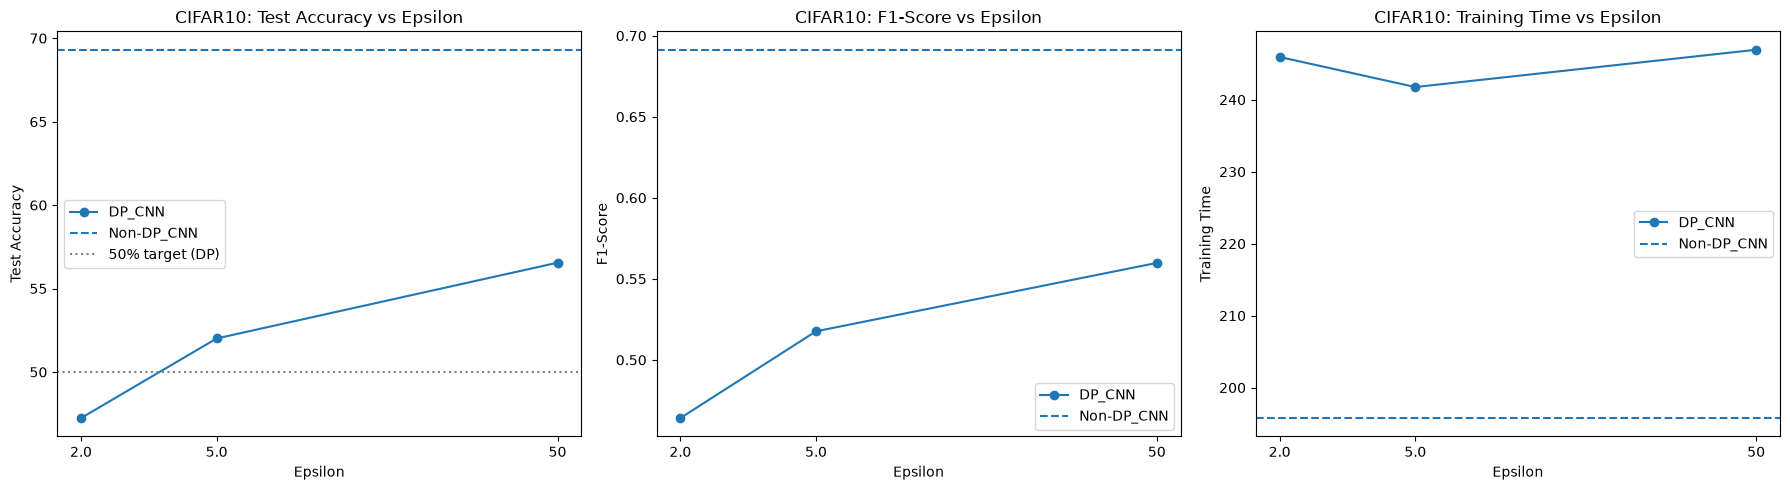

In [116]:
# Plots for CIFAR-10
epsilons = list(dp_results.keys())

accuracies = [dp_results[epsilon]['test_accuracy'] for epsilon in epsilons]
f1_scores = [dp_results[epsilon]['test_f1'] for epsilon in epsilons]
training_times = [dp_results[epsilon]['training_time'] for epsilon in epsilons]

fig,axes = plt.subplots(1, 3, figsize=(18, 5))

# Accuracy
axes[0].plot(epsilons, accuracies, marker='o', label = "DP_CNN")
axes[0].axhline(test_accuracy, linestyle='--', label="Non-DP_CNN")
axes[0].axhline(50, color='gray', linestyle=':', label="50% target (DP)")
axes[0].set_xlabel('Epsilon')
axes[0].set_ylabel('Test Accuracy')
axes[0].set_title('CIFAR10: Test Accuracy vs Epsilon')
axes[0].legend()

# F1-Score
axes[1].plot(epsilons, f1_scores, marker='o', label = "DP_CNN")
axes[1].axhline(test_f1, linestyle='--', label="Non-DP_CNN")
axes[1].set_xlabel('Epsilon')
axes[1].set_ylabel('F1-Score')
axes[1].set_title('CIFAR10: F1-Score vs Epsilon')
axes[1].legend()

# Training Time
axes[2].plot(epsilons, training_times, marker='o', label = "DP_CNN")
axes[2].axhline(training_time, linestyle='--', label="Non-DP_CNN")
axes[2].set_xlabel('Epsilon')
axes[2].set_ylabel('Training Time')
axes[2].set_title('CIFAR10: Training Time vs Epsilon')
axes[2].legend()

for ax in axes:
    ax.set_xscale('log')
    ax.minorticks_off()
    ax.set_xticks(epsilons)
    ax.set_xticklabels(epsilons)


plt.tight_layout()
plt.show()


**CIFAR100 WITHOUT DIFFERENTIAL PRIVACY (Using CNN from Scratch)**

In [117]:
# Import CIFAR100 Dataset
transform_100 = transforms.Compose([transforms.ToTensor(),
                                          transforms.Normalize((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762))]) #CIFAR100 channel mean & std

train_dataset_100 = datasets.CIFAR100(root='./data', train=True, download=True, transform=transform_100)
test_dataset_100 = datasets.CIFAR100(root='./data', train=False, download=True, transform=transform_100)

train_loader_100 = torch.utils.data.DataLoader(train_dataset_100, batch_size=BATCH_SIZE, shuffle=True)
test_loader_100 = torch.utils.data.DataLoader(test_dataset_100, batch_size=BATCH_SIZE, shuffle=False)

In [118]:
# Initialize CNN for CIFAR-100 w/o DP
model_100 = CNN(num_classes=100).to(device)
optimizer_100 = optim.Adam(model_100.parameters(), lr=LR)

# Train w/o DP
train_losses_100, train_accuracies_100, training_time_100 = train(model_100, train_loader_100, optimizer_100, criterion, EPOCHS)
# Test w/o DP
test_loss_100, test_accuracy_100, test_f1_100 = test(model_100, test_loader_100, criterion)

Epoch 1/15: 100%|██████████| 782/782 [00:12<00:00, 64.09it/s]


Epoch 1: Loss = 3.5529, Accuracy = 16.68%


Epoch 2/15: 100%|██████████| 782/782 [00:12<00:00, 64.27it/s]


Epoch 2: Loss = 2.7258, Accuracy = 31.60%


Epoch 3/15: 100%|██████████| 782/782 [00:13<00:00, 60.11it/s]


Epoch 3: Loss = 2.3803, Accuracy = 38.78%


... (20 outputs left out)

Epoch 14/15: 100%|██████████| 782/782 [00:12<00:00, 63.07it/s]


Epoch 14: Loss = 0.9509, Accuracy = 72.03%


Epoch 15/15: 100%|██████████| 782/782 [00:12<00:00, 60.46it/s]


Epoch 15: Loss = 0.8791, Accuracy = 73.98%

Total Training Time: 189.33 seconds
Test Loss: 3.5406, Test Accuracy: 36.49%, Test F1 Score: 0.3631


**CIFAR100 WITH DIFFERENTIAL PRIVACY (Using CNN from Scratch)**

In [119]:
# CIFAR-100 w/ DP
dp_results_100 = {}

for epsilon in EPSILONS:
  print(f"Running DP with epsilon={epsilon}")

  model_dp_100 = CNN(num_classes=100).to(device)
  optimizer_dp_100 = optim.Adam(model_dp_100.parameters(), lr=LR)
  privacy_engine = PrivacyEngine(accountant="rdp")

  model_dp_100, optimizer_dp_100, train_loader_dp_100 = privacy_engine.make_private_with_epsilon(
      module=model_dp_100,
      optimizer=optimizer_dp_100,
      data_loader=train_loader_100,
      epochs=EPOCHS,
      target_epsilon=epsilon,
      target_delta=DELTA,
      max_grad_norm=MAX_GRAD_NORM,
  )

  print(f"Noise Multiplier: {optimizer_dp_100.noise_multiplier:.3f}")

  # train
  train_losses_dp_100, train_accuracies_dp_100, training_time_dp_100 = train(model_dp_100, train_loader_dp_100, optimizer_dp_100, criterion, EPOCHS)
  # test
  test_loss_dp_100, test_accuracy_dp_100, test_f1_dp_100 = test(model_dp_100, test_loader_100, criterion)


  dp_results_100[epsilon] = {
      'train_losses': train_losses_dp_100,
      'train_accuracies': train_accuracies_dp_100,
      'training_time': training_time_dp_100,
      'test_loss': test_loss_dp_100,
      'test_accuracy': test_accuracy_dp_100,
      'test_f1': test_f1_dp_100,
      'epsilon': privacy_engine.get_epsilon(DELTA)
  }


C:\Users\melli\PycharmProjects\Notebooks\.venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
C:\Users\melli\PycharmProjects\Notebooks\.venv\Lib\site-packages\opacus\accountants\analysis\rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(


Running DP with epsilon=2.0
Noise Multiplier: 0.742


Epoch 1/15: 100%|██████████| 781/781 [00:16<00:00, 47.26it/s]


Epoch 1: Loss = 4.5204, Accuracy = 3.09%


Epoch 2/15: 100%|██████████| 781/781 [00:16<00:00, 48.66it/s]


Epoch 2: Loss = 4.2519, Accuracy = 6.63%


... (86 outputs left out)

Epoch 14/15: 100%|██████████| 781/781 [00:17<00:00, 43.95it/s]


Epoch 14: Loss = 3.4252, Accuracy = 20.36%


Epoch 15/15: 100%|██████████| 781/781 [00:15<00:00, 48.89it/s]


Epoch 15: Loss = 3.3925, Accuracy = 21.02%

Total Training Time: 248.75 seconds
Test Loss: 3.5150, Test Accuracy: 19.57%, Test F1 Score: 0.1817


**PLOTS FOR CIFAR100 WITH AND WITHOUT DP (Using CNN from Scratch)**

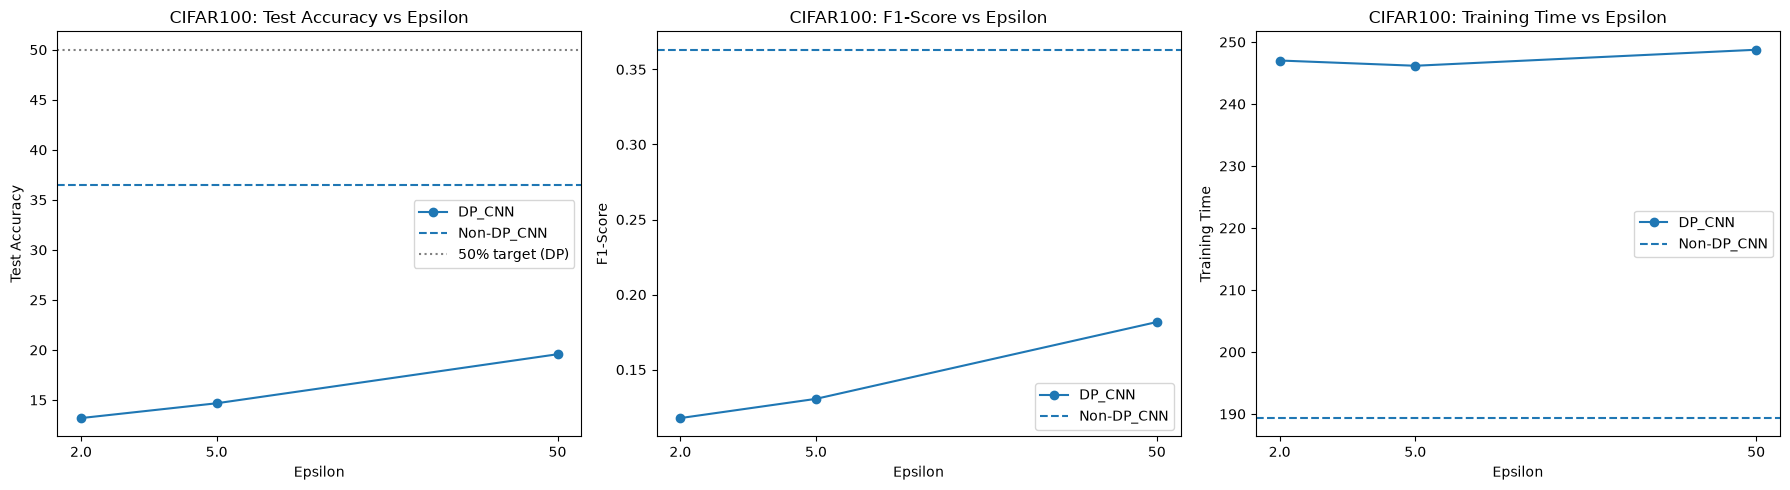

In [120]:
# Plots for CIFAR-100
epsilons_100 = list(dp_results_100.keys())

accuracies_100 = [dp_results_100[epsilon]['test_accuracy'] for epsilon in epsilons_100]
f1_scores_100 = [dp_results_100[epsilon]['test_f1'] for epsilon in epsilons_100]
training_times_100 = [dp_results_100[epsilon]['training_time'] for epsilon in epsilons_100]

fix,axes = plt.subplots(1, 3, figsize=(18, 5))

# Accuracy
axes[0].plot(epsilons_100, accuracies_100, marker='o', label = "DP_CNN")
axes[0].axhline(test_accuracy_100, linestyle='--', label="Non-DP_CNN")
axes[0].axhline(50, color='gray', linestyle=':', label="50% target (DP)")
axes[0].set_xlabel('Epsilon')
axes[0].set_ylabel('Test Accuracy')
axes[0].set_title('CIFAR100: Test Accuracy vs Epsilon')
axes[0].legend()

# F1-Score
axes[1].plot(epsilons_100, f1_scores_100, marker='o', label = "DP_CNN")
axes[1].axhline(test_f1_100, linestyle='--', label="Non-DP_CNN")
axes[1].set_xlabel('Epsilon')
axes[1].set_ylabel('F1-Score')
axes[1].set_title('CIFAR100: F1-Score vs Epsilon')
axes[1].legend()

# Training Time
axes[2].plot(epsilons_100, training_times_100, marker='o', label = "DP_CNN")
axes[2].axhline(training_time_100, linestyle='--', label="Non-DP_CNN")
axes[2].set_xlabel('Epsilon')
axes[2].set_ylabel('Training Time')
axes[2].set_title('CIFAR100: Training Time vs Epsilon')
axes[2].legend()

for ax in axes:
    ax.set_xscale('log')
    ax.minorticks_off()
    ax.set_xticks(epsilons)
    ax.set_xticklabels(epsilons)


plt.tight_layout()
plt.show()


**CIFAR100 (Using frozen pretrained ResNet50)**
Note: This part is computationally heavy so it may take a few minutes (I ran this on my NVIDIA GPU)

In [122]:
from torchvision.models import resnet50, ResNet50_Weights
from torch.utils.data import TensorDataset
import torch.nn.functional as F

backbone = resnet50(weights=ResNet50_Weights.DEFAULT) # Load ResNet50 pretrained weights
backbone.fc = nn.Identity()
backbone = backbone.to(device).eval()

imgN_mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1,3,1,1)
imgN_std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1,3,1,1)

def extract(dataset): # run every image through ResNet once
    X, Y = [], []
    with torch.no_grad(), torch.autocast(device_type='cuda', dtype= torch.float16):
        for images, labels in tqdm(DataLoader(dataset, batch_size=256)):
            images = images.to(device)
            images = F.interpolate(images, size=224, mode='bilinear', align_corners=False)
            images = (images - imgN_mean) / imgN_std
            X.append(backbone(images).float().cpu())
            Y.append(labels)
    return torch.cat(X), torch.cat(Y)

# Extract CIFAR-100 Features
BATCH_SIZE_100 = 256 # Without DP
BATCH_SIZE_DP = 1024 # With DP
LR_100 = 0.001

# Turn CIFAR100 imgs to numbers
transform_100_RN = transforms.ToTensor()
# Save results
X_train_100, y_train_100 = extract(datasets.CIFAR100(root='./data', train=True, transform=transform_100_RN))
X_test_100, y_test_100 = extract(datasets.CIFAR100(root='./data', train=False, transform=transform_100_RN))
# Feed batches of data to model
train_loader_100_RN = DataLoader(TensorDataset(X_train_100, y_train_100), batch_size=BATCH_SIZE_100, shuffle=True)
dp_loader_100_RN = DataLoader(TensorDataset(X_train_100, y_train_100), batch_size=BATCH_SIZE_DP, shuffle=True)
test_loader_100_RN = DataLoader(TensorDataset(X_test_100, y_test_100), batch_size=BATCH_SIZE_100, shuffle=False)

100%|██████████| 40/40 [01:51<00:00,  2.79s/it]


In [124]:
# saving the features to prevent re-running extraction step above:
torch.save((X_train_100, y_train_100, X_test_100, y_test_100), './data/cifar100_resnet50_features.pt')

**CIFAR100 WITHOUT DIFFERENTIAL PRIVACY (Using ResNet50)**

In [125]:
# CIFAR100 w/o DP
model_100_RN = nn.Linear(2048, 100).to(device) # using only the trained part
optimizer_100_RN = optim.Adam(model_100_RN.parameters(), lr=LR_100)

# Train w/o DP
train_losses_100_RN, train_accuracies_100_RN, training_time_100_RN = train(model_100_RN, train_loader_100_RN, optimizer_100_RN, criterion, EPOCHS)
# Test w/o DP
test_loss_100_RN, test_accuracy_100_RN, test_f1_100_RN = test(model_100_RN, test_loader_100_RN, criterion)

Epoch 1/15: 100%|██████████| 196/196 [00:00<00:00, 231.64it/s]


Epoch 1: Loss = 2.2400, Accuracy = 54.89%


Epoch 2/15: 100%|██████████| 196/196 [00:00<00:00, 268.43it/s]


Epoch 2: Loss = 1.1604, Accuracy = 71.04%


Epoch 3/15: 100%|██████████| 196/196 [00:00<00:00, 255.77it/s]


Epoch 3: Loss = 0.9322, Accuracy = 75.53%


... (20 outputs left out)

Epoch 14/15: 100%|██████████| 196/196 [00:00<00:00, 300.44it/s]


Epoch 14: Loss = 0.3800, Accuracy = 90.99%


Epoch 15/15: 100%|██████████| 196/196 [00:00<00:00, 280.19it/s]


Epoch 15: Loss = 0.3589, Accuracy = 91.63%

Total Training Time: 10.34 seconds
Test Loss: 0.8596, Test Accuracy: 74.47%, Test F1 Score: 0.7445


**CIFAR100 WITH DIFFERENTIAL PRIVACY (Using ResNet50)**

In [126]:
# CIFAR-100 w/ DP
dp_results_100_RN = {}

for epsilon in EPSILONS:
  print(f"Running DP with epsilon={epsilon}")

  model_dp_100_RN = nn.Linear(2048, 100).to(device)
  optimizer_dp_100_RN = optim.Adam(model_dp_100_RN.parameters(), lr=LR_100)
  privacy_engine = PrivacyEngine(accountant="rdp")

  model_dp_100_RN, optimizer_dp_100_RN, train_loader_dp_100_RN = privacy_engine.make_private_with_epsilon(
      module=model_dp_100_RN,
      optimizer=optimizer_dp_100_RN,
      data_loader=dp_loader_100_RN,
      epochs=EPOCHS,
      target_epsilon=epsilon,
      target_delta=DELTA,
      max_grad_norm=MAX_GRAD_NORM,
  )

  print(f"Noise Multiplier: {optimizer_dp_100_RN.noise_multiplier:.3f}")

  # train
  train_losses_dp_100_RN, train_accuracies_dp_100_RN, training_time_dp_100_RN = train(model_dp_100_RN, train_loader_dp_100_RN, optimizer_dp_100_RN, criterion, EPOCHS)
  # test
  test_loss_dp_100_RN, test_accuracy_dp_100_RN, test_f1_dp_100_RN = test(model_dp_100_RN, test_loader_100_RN, criterion)


  dp_results_100_RN[epsilon] = {
      'train_losses': train_losses_dp_100_RN,
      'train_accuracies': train_accuracies_dp_100_RN,
      'training_time': training_time_dp_100_RN,
      'test_loss': test_loss_dp_100_RN,
      'test_accuracy': test_accuracy_dp_100_RN,
      'test_f1': test_f1_dp_100_RN,
      'epsilon': privacy_engine.get_epsilon(DELTA)
  }


C:\Users\melli\PycharmProjects\Notebooks\.venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
C:\Users\melli\PycharmProjects\Notebooks\.venv\Lib\site-packages\opacus\accountants\analysis\rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(


Running DP with epsilon=2.0
Noise Multiplier: 1.440


Epoch 1/15: 100%|██████████| 49/49 [00:41<00:00,  1.19it/s]


Epoch 1: Loss = 4.3151, Accuracy = 18.37%


Epoch 2/15: 100%|██████████| 49/49 [00:36<00:00,  1.34it/s]


Epoch 2: Loss = 3.7455, Accuracy = 43.73%


... (82 outputs left out)

Epoch 14/15: 100%|██████████| 49/49 [00:31<00:00,  1.56it/s]


Epoch 14: Loss = 1.0540, Accuracy = 69.90%


Epoch 15/15: 100%|██████████| 49/49 [00:31<00:00,  1.54it/s]

Epoch 15: Loss = 1.0275, Accuracy = 70.66%

Total Training Time: 471.50 seconds
Test Loss: 1.1143, Test Accuracy: 68.40%, Test F1 Score: 0.6787


**PLOTS FOR CIFAR100 WITH AND WITHOUT DP (Using ResNet50)**

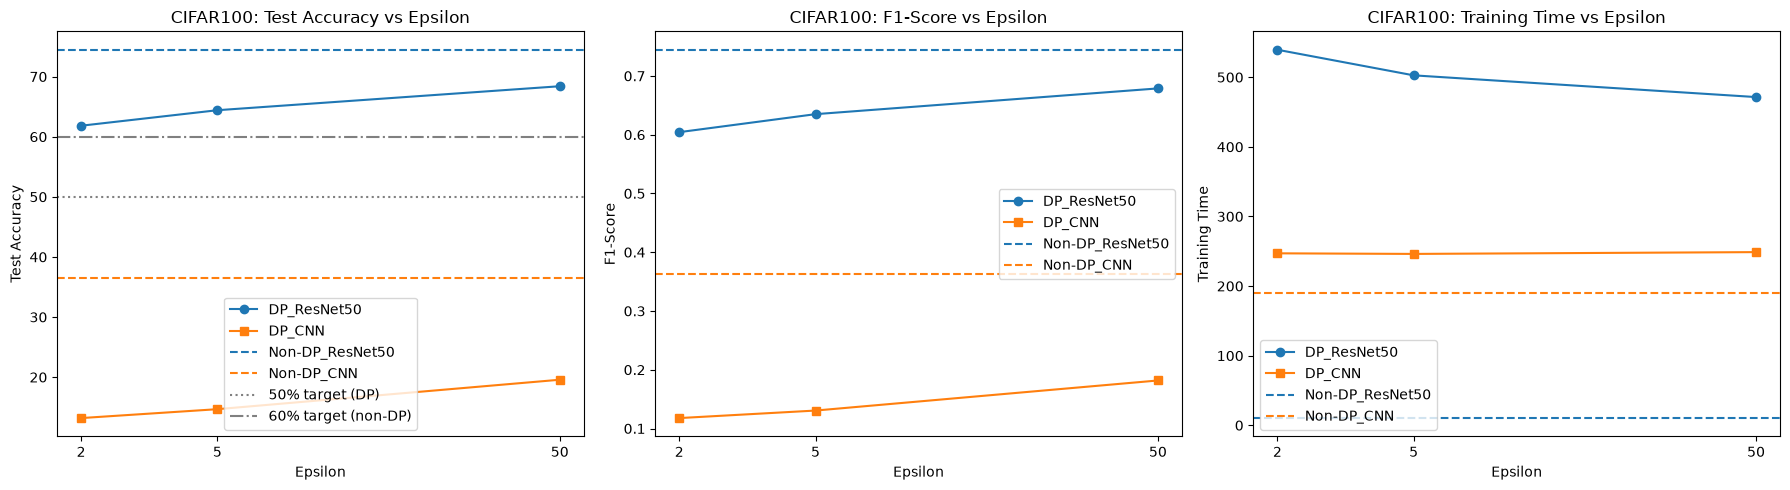

In [127]:
# Plots for CIFAR-100
epsilons_100_RN = list(dp_results_100_RN.keys())

accuracies_100_RN = [dp_results_100_RN[epsilon]['test_accuracy'] for epsilon in epsilons_100_RN]
f1_scores_100_RN = [dp_results_100_RN[epsilon]['test_f1'] for epsilon in epsilons_100_RN]
training_times_100_RN = [dp_results_100_RN[epsilon]['training_time'] for epsilon in epsilons_100_RN]

fix,axes = plt.subplots(1, 3, figsize=(18, 5))

# Accuracy
axes[0].plot(epsilons_100_RN, accuracies_100_RN, marker='o', label = "DP_ResNet50")
axes[0].plot(epsilons_100, accuracies_100, marker='s', label = "DP_CNN")
axes[0].axhline(test_accuracy_100_RN, linestyle='--', color='tab:blue', label="Non-DP_ResNet50")
axes[0].axhline(test_accuracy_100, linestyle='--', color='tab:orange', label="Non-DP_CNN")
axes[0].axhline(50, color='gray', linestyle=':', label="50% target (DP)")
axes[0].axhline(60, color='gray', linestyle='-.', label="60% target (non-DP)")
axes[0].set_xlabel('Epsilon')
axes[0].set_ylabel('Test Accuracy')
axes[0].set_title('CIFAR100: Test Accuracy vs Epsilon')
axes[0].legend()

# F1-Score
axes[1].plot(epsilons_100_RN, f1_scores_100_RN, marker='o', label = "DP_ResNet50")
axes[1].plot(epsilons_100, f1_scores_100, marker='s', label = "DP_CNN")
axes[1].axhline(test_f1_100_RN, linestyle='--', color='tab:blue', label="Non-DP_ResNet50")
axes[1].axhline(test_f1_100, linestyle='--', color='tab:orange', label="Non-DP_CNN")
axes[1].set_xlabel('Epsilon')
axes[1].set_ylabel('F1-Score')
axes[1].set_title('CIFAR100: F1-Score vs Epsilon')
axes[1].legend()

# Training Time
axes[2].plot(epsilons_100_RN, training_times_100_RN, marker='o', label = "DP_ResNet50")
axes[2].plot(epsilons_100, training_times_100, marker='s', label = "DP_CNN")
axes[2].axhline(training_time_100_RN, linestyle='--', color='tab:blue', label="Non-DP_ResNet50")
axes[2].axhline(training_time_100, linestyle='--', color='tab:orange', label="Non-DP_CNN")
axes[2].set_xlabel('Epsilon')
axes[2].set_ylabel('Training Time')
axes[2].set_title('CIFAR100: Training Time vs Epsilon')
axes[2].legend()

for ax in axes:
    ax.set_xscale('log')
    ax.minorticks_off()
    ax.set_xticks(epsilons_100_RN)
    ax.set_xticklabels([f"{e:g}" for e in epsilons_100_RN])


plt.tight_layout()
plt.show()


**Observations**

**4.1 (Architecture)**
- I trained a CNN from scratch using both the CIFAR10 and CIFAR100 datasets. The CNN architecture was designed with two convolution blocks, each with ReLU and max pooling, followed by two fully connected layers.
- A pretrained ResNet50 with a linear layer was used only for the CIFAR100 dataset. All the ResNet50's layers are frozen, and it is only used to turn each image into 2,048 features. Only the single linear layer is trained on CIFAR100, with DP and without DP.

**4.2 (Results)**

CNN from scratch:
- CIFAR10 without DP Metrics: Test Accuracy 69.31%: F1-Score: 0.6913, Total training Time: 195.77 seconds
- CIFAR10 with DP Metrics
    - Epsilon: 2.0
        - Test Accuracy: 47.24% F1-Score: 0.4641, Total training Time: 245.94 seconds
    - Epsilon 5.0
        - Test Accuracy: 52.01% F1-Score: 0.5176, Total training Time: 241.76 seconds
    - Epsilon 50
        - Test Accuracy: 56.55% F1-Score: 0.5598, Total training Time: 246.94 seconds

- CIFAR100 without DP Metrics: Test Accuracy 36.49%: F1-Score: 0.3631, Total training Time: 189.33 seconds
- CIFAR100 with DP Metrics
    - Epsilon: 2.0
        - Test Accuracy: 13.19% F1-Score: 0.1177, Total training Time: 247.02 seconds
    - Epsilon 5.0
        - Test Accuracy: 14.67% F1-Score: 0.1305, Total training Time: 246.16 seconds
    - Epsilon 50
        - Test Accuracy: 19.57% F1-Score: 0.1817, Total training Time: 248.75 seconds

ResNet50:
- CIFAR100 without DP Metrics: Test Accuracy 74.47%: F1-Score: 0.7445, Total training Time: 10.34 seconds
- CIFAR100 with DP Metrics
    - Epsilon: 2.0
        - Test Accuracy: 61.83% F1-Score: 0.6043, Total training Time: 539.47 seconds
    - Epsilon 5.0
        - Test Accuracy: 64.41% F1-Score: 0.6349, Total training Time: 502.70 seconds
    - Epsilon 50
        - Test Accuracy: 68.40% F1-Score: 0.6787, Total training Time: 471.50 seconds

**4.3 (Other Observations)**
- As shown in the results, the stronger the privacy (lower epsilon), the lower the accuracy. As epsilon increased from 2.0 to 50.0, accuracy increased for every model. For example, epsilon 50.0 gave higher accuracies compared to epsilon 2.0, therefore, more noise made it difficult for the model to learn.
- Training time took longer with differential privacy. For example, on my CNN model from scratch (CIFAR10), training without DP took 195.77 seconds, whereas with DP it jumped to ~ 246 seconds.
- Overfitting happened in the models trained without DP. For example, on CNN CIFAR10 w/o DP, the model's training accuracy was 97.33%, yet on unseen data (test data), it dropped down to 69.31%. When I trained the same CNN on CIFAR10 w/ DP, the training and testing accuracies were similar, meaning DP removed the overfitting

Why did I implement ResNet50?
- While the CIFAR10 dataset performed fine on the CNN I created from scratch, CIFAR100 did not do well on the CNN. Even after adding more convolutional layers to help the model learn the CIFAR100 dataset, the accuracies were still too low and training took too long (I've kept the original CNN's CIFAR100 results in as a reference). After doing some research, including Opacus's "Building an Image Classifier with Differential Privacy" (which uses ResNet), I used a pretrained ResNet50 to help the model learn CIFAR100, since it has more classes.

Hyperparameter tuning
- Reducing the LR from 0.001 to 0.0005 resulted in lower training accuracy rather than improvement. Therefore, an LR of 0.001 was kept.
- After experimenting with different epochs, 15 epochs were selected. Increasing or decreasing the number of epochs did not make a difference with training and testing accuracies.
- Increasing the max gradient norm from 1.0 to 2.0 improved the (from scratch) CNN's performance on both test and train accuracies.